# Imports

In [1]:
import kagglehub
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Random State

We used seed 42 as our default change this to obtain different results

In [2]:
superRandomSeedVariable = 42

trainTestSplitSeed = superRandomSeedVariable
np.random.seed(superRandomSeedVariable)

# Data Loading and Preprocessing

In [3]:
# Getting Data from kaggle using kagglehub, reading from the same using read_csv and storing the same in a Pandas Dataframe

path = kagglehub.dataset_download("blastchar/telco-customer-churn")
df = pd.read_csv(path + "/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Dropping the Unique Columns
df = df.drop("customerID",axis=1)

df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce") # Conversion. This feature was initially stored as text in the dataset.

# Dropping all records with any null values
df = df.dropna()

# Mapping Features and Targets
y = df["Churn"].map({"Yes":1,"No": 0}).values
X = df.drop("Churn",axis=1)

# Force Converting all numerical columns into pandas numeric type using to_numeric and filling any potential null values with mean
numeric_features = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
df[numeric_features] = df[numeric_features].apply(pd.to_numeric, errors="coerce")
df[numeric_features] = df[numeric_features].fillna(df[numeric_features].mean()) # Potential Null values created when forcefully converting


categorical_features = df.drop(columns=["Churn"] + numeric_features).select_dtypes(include=["object"]).columns

print("Categorical Features: ", len(categorical_features))
print("Numerical Features: ", len(numeric_features))
df.head()


Categorical Features:  15
Numerical Features:  4


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Data Encoding

In [4]:
X_encoded= pd.get_dummies(X,columns=categorical_features,drop_first=True)
print(X_encoded.shape)

(7032, 30)


# Train Test Validation Split

In [5]:
X_np=np.array(X_encoded,dtype=np.float32)
y_np=np.array(y).reshape(-1,1)

# Train validation test split
X_train,X_val_test,y_train,y_val_test=train_test_split(X_np,y_np,test_size=0.3,random_state=trainTestSplitSeed,stratify=y_np)

X_val,X_test,y_val,y_test=train_test_split(X_val_test,y_val_test,test_size=0.5,random_state=trainTestSplitSeed,stratify=y_val_test)

# Appliying Standard Scaler
scaler=StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

In [6]:
# Printing the Shapes of the Train, Test and Validation sets
print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)

# Printing the Churn Rate (aka the average rate a person would churn for the respective sets)
print("Churn rate (train):", y_train.mean())
print("Churn rate (val):  ", y_val.mean())
print("Churn rate (test): ", y_test.mean())


Train: (4922, 30) (4922, 1)
Val:   (1055, 30) (1055, 1)
Test:  (1055, 30) (1055, 1)
Churn rate (train): 0.2657456318569687
Churn rate (val):   0.2663507109004739
Churn rate (test):  0.26540284360189575


# Linear Model

Params:

1) input: Number of Input Nodes
2) output: Number of Output Nodes
3) lambda_l1: Value of l1 regularizer (Default = 0.0)
4) lambda_l2: Value of l2 regularizer (Default = 0.0)

Methods:

1) forward_pass: Calculates output when doing forwardpropagation
2) backward_pass: Calculates Derivates when doing backpropagation

In [7]:
class LinearImplementation:
    def __init__(self,input,output,lambda_l1=0.0,lambda_l2=0.0):
        self.W=np.random.randn(input,output)*np.sqrt(2.0/input)
        self.b=np.zeros((1,output))
        self.X=None  
        self.lambda_l1=lambda_l1
        self.lambda_l2=lambda_l2
    
    def forward_pass(self,X):
        self.X=X
        z=X @ self.W + self.b
        return z
    
    def backward_pass(self,dz):
        m=len(self.X)
        self.dW = self.X.T @ dz
        self.dW /=m

        self.db= np.sum(dz,axis=0,keepdims=True)
        self.db /=m

        if self.lambda_l1 >0:
            self.dW += self.lambda_l1 * np.sign(self.W)

        if self.lambda_l2>0:
            self.dW+= self.lambda_l2*2*self.W
            
        dX=dz @ self.W.T
        return dX

## testing Linear layer shapes

In [8]:

batch_size = 4
i = 4
o= 2

X = np.random.randn(batch_size, i)
layer = LinearImplementation(i, o)
Z = layer.forward_pass(X)

dZ = np.random.randn(batch_size, o)
dX = layer.backward_pass(dZ)

print("input shape:",X.shape)
print("Output shape after forward propagation:", Z.shape)
print("Gradient shape after back propagation:", dX.shape)

print(layer.dW)
print(layer.dW.shape)
print(layer.db)
print(layer.db.shape)

input shape: (4, 4)
Output shape after forward propagation: (4, 2)
Gradient shape after back propagation: (4, 4)
[[ 0.03387515  0.13806251]
 [ 0.29252741 -0.95137251]
 [-0.2135033  -0.5986753 ]
 [-0.27358904 -0.11210009]]
(4, 2)
[[-0.7244304   0.51180126]]
(1, 2)


# ReLU and Sigmoid Layers

## ReLU

Methods:

1) forward_pass: Calculates output of ReLU when doing forward propagation
2) backward_pass: Calculates Derivates of ReLU when doing backpropagation

In [9]:
class ReLU:
    def __init__(self):
        self.z=None

    def forward_pass(self,z):
        self.z=z
        return np.maximum(0,z)
        
    def backward_pass(self,dA):
        dz=dA.copy()
        dz[self.z<=0]=0
        return dz    




## Testing ReLU layer Shape

In [10]:
relu = ReLU()

z = np.random.randn(4, 16)
A = relu.forward_pass(z)

dA=np.random.randn(4,16)
dZ=relu.backward_pass(dA)
print("input shape:",z.shape)
print("Output shape after forward propagation:", A.shape)
print("Gradient shape after back propagation:", dZ.shape)

input shape: (4, 16)
Output shape after forward propagation: (4, 16)
Gradient shape after back propagation: (4, 16)


## Sigmoid

Methods:

1) forward_pass: Calculates output of Sigmoid when doing forward propagation
2) backward_pass: Calculates Derivates of Sigmoid when doing backpropagation

In [11]:
class Sigmoid:
    def __init__(self):
        pass

    def forward_pass(self,z):
        A=1/(1+np.exp(-z))
        self.A=A
        return A
    
    def backward_pass(self,dA):
        dz=dA* (self.A*(1-self.A))
        return dz


## Testing ReLU layer Shape

In [12]:
sigmoid_test=Sigmoid()
z=np.random.randn(4,1)
A=sigmoid_test.forward_pass(z)

dA=np.random.randn(4,1)
dz=sigmoid_test.backward_pass(dA)

print("input shape:",z.shape)
print("Output shape after forward propagation:", A.shape)
print("Gradient shape after back propagation:", dz.shape)

input shape: (4, 1)
Output shape after forward propagation: (4, 1)
Gradient shape after back propagation: (4, 1)


# Softmax Layer

Methods:

1) forward_pass: Calculates output of Softmax when doing forward propagation
2) backward_pass: Calculates Derivates of Softmax when doing backpropagation

In [13]:
class Softmax:
    def __init__(self):
        pass

    def forward_pass(self,z):
        z_norm = z -np.max(z,axis=1,keepdims=True)
        exp_z=np.exp(z_norm)
        A=exp_z/np.sum(exp_z,axis=1,keepdims=True)
        self.A=A
        return A
    
    def backward_pass(self,dA):        
        return dA              #taking into account that the derivative of softmax combined with CE Loss is A - Y, basically it gets skipped

# Performance metrics

In [14]:
class Accuracy:
    def acc(self,yHat,y):
        preds = (yHat >=0.5).astype(int)
        return np.mean(preds ==y)
        

In [15]:
class BinaryCrossEntropyLoss:

    def forward_pass(self, yHat, y):
        epsilon = 1e-15
        self.yHat = np.clip(yHat, epsilon, 1 - epsilon)
        self.y = y
        loss_value = -np.mean(
            y * np.log(self.yHat) +
            (1 - y) * np.log(1 - self.yHat)
        )
        return loss_value

    def backward_pass(self, y):
        N = y.shape[0]
        dA = (self.yHat - y) / N
        return dA


In [16]:
class CategoricalCELoss:
    def __init__(self):
        self.yHat = None
        self.y = None

    def forward_pass(self,yHat,y):
        epsilon=1e-15
        self.y=y
        self.yHat=np.clip(yHat,epsilon,1-epsilon)
        loss=-np.mean(np.sum(y * np.log(self.yHat), axis=1))
        return loss
    
    def backward_pass(self, Y):
        N = Y.shape[0]
        dz = (self.yHat - Y) / N
        return dz


z = np.array([[2.0, 1.0, 0.1]])
y = np.array([[1, 0, 0]])

softmax = Softmax()
cce = CategoricalCELoss()

a = softmax.forward_pass(z)
loss = cce.forward_pass(a, y)
dZ = cce.backward_pass()

print("Probabilities:", a)
print("Sum:", np.sum(a))
print("Loss:", loss)
print("dZ:", dZ)

# Optimizers

Params:

1) lr: Learning rate (Default = 0.01)
2) mu: Momentum Coefficient (Default = 0.9) (Exclusive for SGDMomentum())

Methods:

1) update_parameters: Updates the weights and biases

In [17]:
class SGDOptimizer:
    def __init__(self,lr=0.01):
        self.lr=lr
    
    def update_parameters(self,layers):
        for l in layers:
            if isinstance(l,CustomLinearImplementation):
                l.W-=self.lr*l.dW
                l.b-=self.lr*l.db

In [18]:
class SGDMomentum:
    def __init__(self,lr=0.01,mu=0.9):
        self.lr = lr
        self.mu = mu

    def update_parameters(self,layers):
        for i in layers:
            if isinstance(i,CustomLinearImplementation):
                i.W = self.mu * i.W - self.lr*i.dW
                i.b = self.mu * i.b - self.lr*i.db

# Dropout

Params:

1) prob: probability of disabling the neuron (Default = 0.5)
2) inv: Applying inverted dropout (Default = True)


Methods:

1) forward_pass: Calculates the mask for dropout and apply it when doing forward propagation
2) backward_pass: Apply the mask obtained during forward_pass onto the derivate when doing backpropagation

In [19]:
class Dropout:
    def __init__(self, prob:float = 0.5, inv:bool=True):
        if inv == True:
            self.prob = 1 - prob
        else:
            self.prob = prob
        self.mask = None
        self.outFeat = None
        self.inv = inv

    def forward_pass(self,x,eval=False):
        if not isinstance(x, np.ndarray):
            x = np.array(x)

        if self.outFeat is None:
            self.outFeat = x.shape[-1]
        if not eval:
            if self.inv == True:
                self.mask = (np.random.rand(*x.shape) < self.prob) / self.prob
            else:
                self.mask = (np.random.rand(*x.shape) < self.prob)    
            return x*self.mask
        else:
            return x
    
    def backward_pass(self, dA):
        return dA * self.mask


## Testing Dropout

In [20]:
batch_size = 4
i = 5

X = np.random.randn(batch_size, i)
layer = Dropout(0.7)
Z = layer.forward_pass(X)

dZ = np.random.randn(batch_size, i)
dX = layer.backward_pass(dZ)

print("input shape:",X.shape)
print("input:",X)
print("Output shape after forward propagation:", Z.shape)
print("Output after forward propagation:", Z)
print("gradient:",dZ)
print("Gradient shape after back propagation:", dX.shape)
print("Gradient after back propagation:", dX)

input shape: (4, 5)
input: [[-0.24538812 -0.75373616 -0.88951443 -0.81581028 -0.07710171]
 [ 0.34115197  0.2766908   0.82718325  0.01300189  1.45353408]
 [-0.26465683  2.72016917  0.62566735 -0.85715756 -1.0708925 ]
 [ 0.48247242 -0.22346279  0.71400049  0.47323762 -0.07282891]]
Output shape after forward propagation: (4, 5)
Output after forward propagation: [[-0.         -0.         -2.9650481  -0.         -0.        ]
 [ 0.          0.92230266  0.          0.          0.        ]
 [-0.          9.06723056  0.         -0.         -3.56964166]
 [ 0.         -0.          0.          0.         -0.        ]]
gradient: [[-1.37766937 -0.93782504  0.51503527  0.51378595  0.51504769]
 [ 3.85273149  0.57089051  1.13556564  0.95400176  0.65139125]
 [-0.31526924  0.75896922 -0.77282521 -0.23681861 -0.48536355]
 [ 0.08187414  2.31465857 -1.86726519  0.68626019 -1.61271587]]
Gradient shape after back propagation: (4, 5)
Gradient after back propagation: [[-0.         -0.          1.71678422  0.   

# Modification of the Linear Model

Params:

1) input: The number of input nodes
2) output: The number of output nodes
3) act: The activation function (None, ReLU(), Sigmoid()) (Default = None)
4) drop: The dropout function (None, Dropout()) (Default = None)
5) lambda_l1: L1 value (Default = 0.0)
6) lambda_l2: L2 value (Default = 0.0)
7) uni: Unique Value to identify the Linear Layer (Default = 0)

Methods:

Methods:

1) forward_pass: Calculates the output by applying forward propagation of Activation Function and Dropout in order when doing forward propagation
2) backward_pass: Calculates the derivate of input by applying backpropagation of Dropout and Activation Function in order when doing backpropagation

In [21]:
class CustomLinearImplementation:
    def __init__(self,input,output,act=None,drop=None,lambda_l1=0.0,lambda_l2=0.0,uni=0):
        self.W=np.random.randn(input,output)*np.sqrt(2.0/input)
        self.b=np.random.randn(1,output)*0.001
        self.dW=np.zeros((input,output))
        self.dB=np.zeros((1,output))
        self.X=None
        self.dX=None
        self.lambda_l1=lambda_l1
        self.lambda_l2=lambda_l2
        self.act = act
        self.drop = drop
        self.uni = uni
    
    def forward_pass(self,X):
        self.X=X

        # Applying Activation Forward Pass
        if self.act != None:
            self.X = self.act.forward_pass(self.X)
        else:
            self.X = self.X

        # Applying Dropout Forward Pass
        if self.drop != None:
            self.X = self.drop.forward_pass(self.X)
        else:
            self.X = self.X

        # Calculating output
        z=self.X @ self.W + self.b
        return z
    
    def backward_pass(self,dz):
        m=len(self.X)

        # Calculating derivated of Weights
        self.dW = self.X.T @ dz
        self.dW /=m

        # Calculating derivated of Bias
        self.db= np.sum(dz,axis=0,keepdims=True)
        self.db /=m

        # L1 and L2 regularizers
        if self.lambda_l1 >0:
            self.dW += self.lambda_l1 * np.sign(self.W)

        if self.lambda_l2>0:
            self.dW+= self.lambda_l2*2*self.W

        # Calculating derivate for X with respect to output
        self.dX=dz @ self.W.T

        # Applying Dropout Backward Pass
        if self.drop != None:
            self.dX = self.drop.backward_pass(self.dX)
        else:
            self.dX = self.dX

        # Applying Activation function Backward Pass and calculating derivative of X
        if self.act != None:
            self.dX = self.dX * self.act.backward_pass(self.dX)
        else:
            self.dX = self.dX

        
        return self.dX

## Custom Linear Model layer shape check

In [22]:
batch_size = 4
i = 4
o= 2

X = np.random.randn(batch_size, i)
layer = CustomLinearImplementation(i, o)
Z = layer.forward_pass(X)

dZ = np.random.randn(batch_size, o)
dX = layer.backward_pass(dZ)

print("input shape:",X.shape)
print("input:",X)
print("Output shape after forward propagation:", Z.shape)
print("Output after forward propagation:", Z)
print("Gradient shape after back propagation:", dX.shape)
print("Gradient after back propagation:", dX)

print(layer.dW)
print(layer.dW.shape)
print(layer.dB)
print(layer.dB.shape)

input shape: (4, 4)
input: [[-0.47193187  1.0889506   0.06428002 -1.07774478]
 [-0.71530371  0.67959775 -0.73036663  0.21645859]
 [ 0.04557184 -0.65160035  2.14394409  0.63391902]
 [-2.02514259  0.18645431 -0.66178646  0.85243333]]
Output shape after forward propagation: (4, 2)
Output after forward propagation: [[ 0.96246671  1.18801404]
 [ 1.19248497  0.54722939]
 [-2.288986   -1.20214671]
 [ 1.47863239  0.04157996]]
Gradient shape after back propagation: (4, 4)
Gradient after back propagation: [[ 6.32128338e-01  1.11661630e-01  8.53059649e-01 -5.76376489e-04]
 [-1.27301437e+00  1.38983538e+00 -2.04536107e+00 -1.18967030e+00]
 [ 8.90736403e-01 -8.38975598e-01  1.40408158e+00  7.33964052e-01]
 [-6.52559067e-01  1.91664817e-02 -9.07891583e-01 -9.85511416e-02]]
[[-0.88946277  0.0598424 ]
 [ 0.32385382  0.47118661]
 [-1.43171766 -0.31623067]
 [ 0.48376745 -0.41898529]]
(4, 2)
[[0. 0.]]
(1, 2)


# Custom Fully Parameterized Neural Network Class

Params:

1) inputLayers: An array of Layers, aka architecture of the neural network
2) loss: Loss Function (BinaryCrossEntropyLoss(), CategoricalCELoss()) (Default = BinaryCrossEntropyLoss())
3) optimize: Optimizer function (None,SGDOptimizer(),SGDMomentum()) (Default = None)

Methods:

1) forward_pass: Iterates through the inputLayer and applies forward pass for each layer
2) backward_pass: Iterates backwards throught the inputLayer and applies back pass for each layer
3) singleTrainStep: Trains the model and calculates the predicted Y value, updates parameters and Calcuates Loss and Accuracy
4) train: Runs singleTrainStep for specified number of epochs (Default = 100), prints loss and accuracy graph and prints the highest accuracy achieved
5) test: Returns Accuracy and loss for the trained model by running through forward pass 

In [23]:
class CustomNeuralNetwork:
    def __init__(self,
inputLayers = [CustomLinearImplementation(30,15),CustomLinearImplementation(15,1),Softmax()],
loss=BinaryCrossEntropyLoss(),
optimize=None):
        self.X = None
        self.Y = None
        self.layers = inputLayers
        self.lambda_l1 = 0.0
        self.lambda_l2 = 0.0
        self.loss = loss
        self.optimize = optimize
        self.acc = Accuracy() 

    def forward_pass(self,X):
        self.X = X
        for i in self.layers:
            self.X = i.forward_pass(self.X)
        return self.X

    def backward_pass(self, Y):
        dA = self.loss.backward_pass(Y)
        for layer in self.layers[::-1]:
            dA = layer.backward_pass(dA)


    def singleTrainStep(self,X,Y):
        yHat = self.forward_pass(X)
        loss = self.loss.forward_pass(yHat,Y)
        acc = self.acc.acc(yHat,Y)
        self.backward_pass(Y)

        if self.optimize != None:
            self.optimize.update_parameters(self.layers)
        else:
            for l in layers:
                if isinstance(l,CustomLinearImplementation):
                    l.W-=self.lr
                    l.b-=self.lr
        return loss,acc
        
    def train(self,X,Y,epochs=100):
        ep = np.arange(0,100,1)
        lossArr = []
        accArr = []
        for i in range(epochs):
            loss,acc = self.singleTrainStep(X,Y)
            lossArr.append(loss)
            accArr.append(acc)
            print("Epoch: ",i," | Accuracy: ",acc," | Loss: ",loss)
        
        fig, (ax1,ax2) = plt.subplots(2,1)
        color = 'tab:red'
        ax1.set_xlabel('Number of Epochs') 
        ax1.set_ylabel('Loss', color = color) 
        ax1.plot(ep, lossArr, color = color) 
        ax1.tick_params(axis ='y', labelcolor = color) 
        ax1.legend(['Loss'])
        
        color = 'tab:green'
        ax2.set_xlabel('Number of Epochs') 
        ax2.set_ylabel('Acc', color = color) 
        ax2.plot(ep, accArr, color = color) 
        ax2.tick_params(axis ='y', labelcolor = color) 
        ax2.legend(['Accuracy'])
        
        fig.suptitle("Loss vs Accuracy", fontweight ="bold") 
        fig.tight_layout()
        plt.show()

        print("Highest Accuracy",max(accArr))

    def test(self,X,Y):
        yHat = self.forward_pass(X)
        loss = self.loss.forward_pass(yHat,Y)
        acc = self.acc.acc(yHat,Y)

        print("Accuracy: ",acc," | Loss: ",loss)
        
        
            

## Testing Custom Neural Network Architectures

### Params (Testing for a funnel Sigmoid architecture)

Layers: Linear(30,20),Sigmoid(),Dropout(prob=0.25),Linear(20,10),Sigmoid(),Dropout(prob=0.25),Linear(20,1),Sigmoid()

Loss: BinaryCrossEntropyLoss()

Optimize: SGDOptimizer(lr=0.01)

Epoch:  0  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  1  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  2  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  3  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  4  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  5  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  6  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  7  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  8  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  9  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  10  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  11  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  12  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  13  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Ep

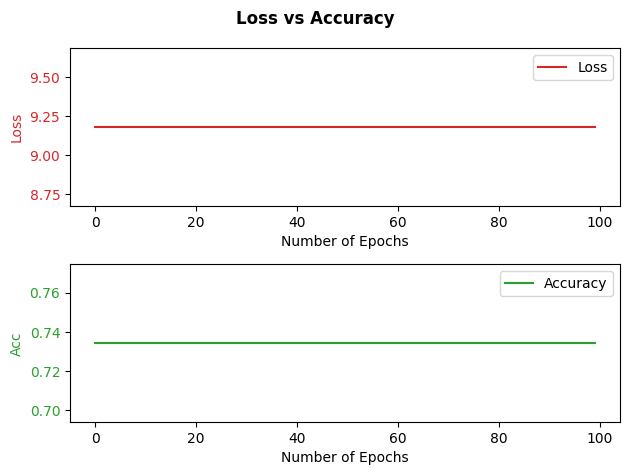

Highest Accuracy 0.7342543681430312
Accuracy:  0.7345971563981043  | Loss:  9.166689469739328
Accuracy:  0.7336492890995261  | Loss:  9.199427646416968


In [24]:
X = X_train
Y = y_train

model1 = CustomNeuralNetwork(
            inputLayers = [
                CustomLinearImplementation(30,20,act=Sigmoid(),drop=Dropout(0.25,inv=False),uni=1),
                CustomLinearImplementation(20,10,act=Sigmoid(),drop=Dropout(0.25,inv=False),uni=2),
                CustomLinearImplementation(10,1,act=Sigmoid(),uni=3)
                ],
            loss=BinaryCrossEntropyLoss(),
            optimize=SGDOptimizer(lr=0.01))

model1.train(X,Y,epochs=100)

model1.test(X_test,y_test)
model1.test(X_val,y_val)

### Params (Testing for a funnel ReLU architecture)

Layers: Linear(30,20),ReLU(),Dropout(prob=0.25),Linear(20,10),ReLU(),Dropout(prob=0.25),Linear(20,1),Sigmoid()

Loss: BinaryCrossEntropyLoss()

Optimize: SGDOptimizer(lr=0.01)

Epoch:  0  | Accuracy:  0.7342543681430312  | Loss:  9.178530524932496
Epoch:  1  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  2  | Accuracy:  0.7342543681430312  | Loss:  9.178533993066983
Epoch:  3  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  4  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  5  | Accuracy:  0.7342543681430312  | Loss:  9.17853796047165
Epoch:  6  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  7  | Accuracy:  0.7342543681430312  | Loss:  9.178552473462481
Epoch:  8  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  9  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  10  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  11  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  12  | Accuracy:  0.7342543681430312  | Loss:  9.178545157265123
Epoch:  13  | Accuracy:  0.7342543681430312  | Loss:  9.178535079951969
Epo

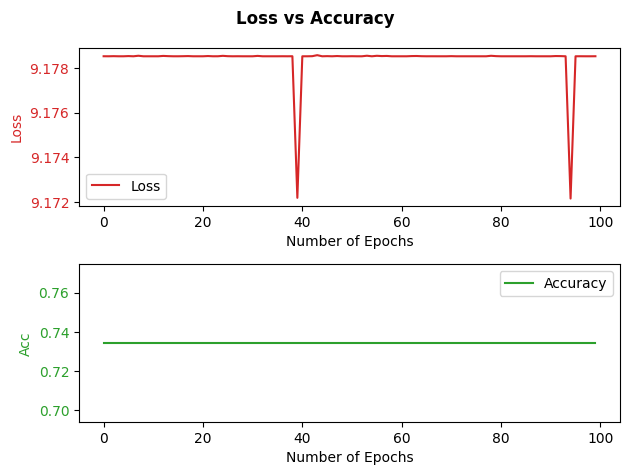

Highest Accuracy 0.7342543681430312
Accuracy:  0.7345971563981043  | Loss:  9.166689469739328
Accuracy:  0.7336492890995261  | Loss:  9.199427646416968


In [25]:
X = X_train
Y = y_train

model2 = CustomNeuralNetwork(
            inputLayers = [
                CustomLinearImplementation(30,20,act=ReLU(),drop=Dropout(0.25,inv=False),uni=1),
                CustomLinearImplementation(20,10,act=ReLU(),drop=Dropout(0.25,inv=False),uni=2),
                CustomLinearImplementation(10,1,act=Sigmoid(),uni=3)
                ],
            loss=BinaryCrossEntropyLoss(),
            optimize=SGDOptimizer(lr=0.01))

model2.train(X,Y,epochs=100)

model2.test(X_test,y_test)
model2.test(X_val,y_val)

### Params (Testing for a funnel Mixed architecture)

Layers: Linear(30,20),Sigmoid(),Dropout(prob=0.25),Linear(20,10),ReLU(),Dropout(prob=0.25),Linear(20,1),Sigmoid()

Loss: BinaryCrossEntropyLoss()

Optimize: SGDOptimizer(lr=0.01)


Epoch:  0  | Accuracy:  0.2657456318569687  | Loss:  1.652044653289127
Epoch:  1  | Accuracy:  0.2657456318569687  | Loss:  1.6315211436003583
Epoch:  2  | Accuracy:  0.2657456318569687  | Loss:  1.6473679253738942
Epoch:  3  | Accuracy:  0.2657456318569687  | Loss:  1.6274640744128008
Epoch:  4  | Accuracy:  0.2657456318569687  | Loss:  1.6267148135268268
Epoch:  5  | Accuracy:  0.2657456318569687  | Loss:  1.645720541812181
Epoch:  6  | Accuracy:  0.2657456318569687  | Loss:  1.6203344241152235
Epoch:  7  | Accuracy:  0.2657456318569687  | Loss:  1.658168758112533
Epoch:  8  | Accuracy:  0.2657456318569687  | Loss:  1.6368719808189052
Epoch:  9  | Accuracy:  0.2657456318569687  | Loss:  1.6379380797624288
Epoch:  10  | Accuracy:  0.2657456318569687  | Loss:  1.6082354059181854
Epoch:  11  | Accuracy:  0.2657456318569687  | Loss:  1.6327386916183282
Epoch:  12  | Accuracy:  0.2657456318569687  | Loss:  1.6635389443499538
Epoch:  13  | Accuracy:  0.2657456318569687  | Loss:  1.61793092

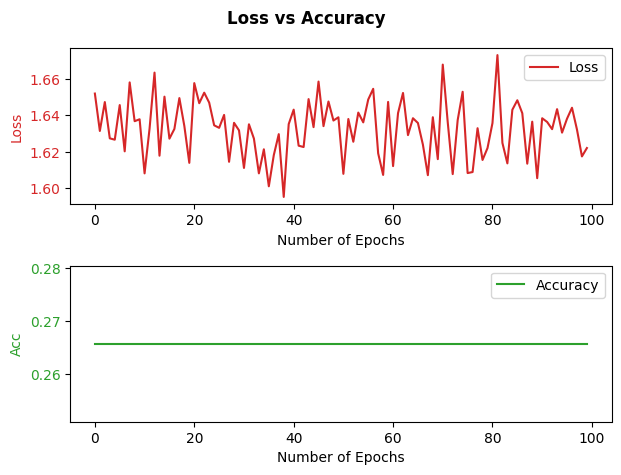

Highest Accuracy 0.2657456318569687
Accuracy:  0.26540284360189575  | Loss:  1.6034329557308118
Accuracy:  0.2663507109004739  | Loss:  1.6266742087654305


In [26]:
X = X_train
Y = y_train

model3 = CustomNeuralNetwork(
            inputLayers = [
                CustomLinearImplementation(30,20,act=Sigmoid(),drop=Dropout(0.25,inv=False),uni=1),
                CustomLinearImplementation(20,10,act=ReLU(),drop=Dropout(0.25,inv=False),uni=2),
                CustomLinearImplementation(10,1,act=Sigmoid(),uni=3)
                ],
            loss=BinaryCrossEntropyLoss(),
            optimize=SGDOptimizer(lr=0.01))

model3.train(X,Y,epochs=100)

model3.test(X_test,y_test)
model3.test(X_val,y_val)

### Params (Testing for a Mixed architecture)

Layers: Linear(30,60),Sigmoid(),Dropout(prob=0.25),Linear(60,80),Sigmoid(),Dropout(prob=0.25),Linear(80,40),Sigmoid(),Dropout(prob=0.25),Linear(40,20),Sigmoid(),Dropout(prob=0.25),Linear(20,10),ReLU(),Dropout(prob=0.25),Linear(10,1),Sigmoid()

Loss: BinaryCrossEntropyLoss()

Optimize: SGDOptimizer(lr=0.01)


Epoch:  0  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  1  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  2  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  3  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  4  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  5  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  6  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  7  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  8  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  9  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  10  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  11  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  12  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  13  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Ep

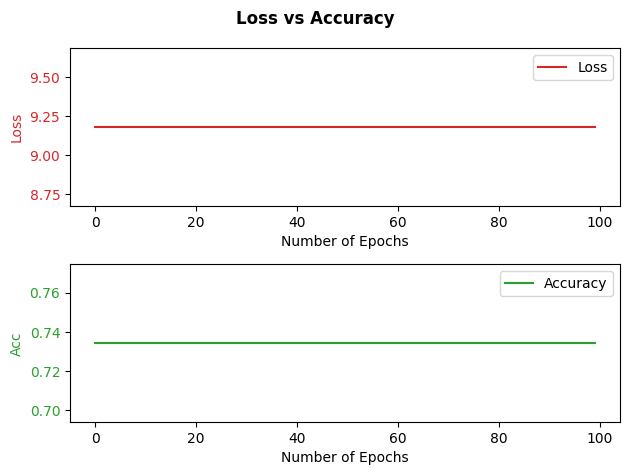

Highest Accuracy 0.7342543681430312
Accuracy:  0.7345971563981043  | Loss:  9.166689469739328
Accuracy:  0.7336492890995261  | Loss:  9.199427646416968


In [27]:
X = X_train
Y = y_train

model4 = CustomNeuralNetwork(
            inputLayers = [
                CustomLinearImplementation(30,60,act=ReLU(),drop=Dropout(0.25,inv=False),uni=1),
                CustomLinearImplementation(60,80,act=Sigmoid(),drop=Dropout(0.25,inv=False),uni=2),
                CustomLinearImplementation(80,40,act=ReLU(),drop=Dropout(0.25,inv=False),uni=3),
                CustomLinearImplementation(40,20,act=Sigmoid(),drop=Dropout(0.25,inv=False),uni=4),
                CustomLinearImplementation(20,10,act=ReLU(),drop=Dropout(0.25,inv=False),uni=5),
                CustomLinearImplementation(10,1,act=Sigmoid(),uni=6)
                ],
            loss=BinaryCrossEntropyLoss(),
            optimize=SGDOptimizer(lr=0.01))

model4.train(X,Y,epochs=100)

model4.test(X_test,y_test)
model4.test(X_val,y_val)

### Params

Layers: Linear(30,15),ReLU(),Dropout(prob=0.2),Linear(15,1),ReLU(),Dropout(prob=0.1),Softmax()

Loss: CategoricalCELoss()

Optimize: optimize=SGDMomentum(lr=0.1,mu=0.85)

Epoch:  0  | Accuracy:  0.2657456318569687  | Loss:  2.655332272630506e-16
Epoch:  1  | Accuracy:  0.2657456318569687  | Loss:  2.655332272630506e-16
Epoch:  2  | Accuracy:  0.2657456318569687  | Loss:  2.655332272630506e-16
Epoch:  3  | Accuracy:  0.2657456318569687  | Loss:  2.655332272630506e-16
Epoch:  4  | Accuracy:  0.2657456318569687  | Loss:  2.655332272630506e-16
Epoch:  5  | Accuracy:  0.2657456318569687  | Loss:  2.655332272630506e-16
Epoch:  6  | Accuracy:  0.2657456318569687  | Loss:  2.655332272630506e-16
Epoch:  7  | Accuracy:  0.2657456318569687  | Loss:  2.655332272630506e-16
Epoch:  8  | Accuracy:  0.2657456318569687  | Loss:  2.655332272630506e-16
Epoch:  9  | Accuracy:  0.2657456318569687  | Loss:  2.655332272630506e-16
Epoch:  10  | Accuracy:  0.2657456318569687  | Loss:  2.655332272630506e-16
Epoch:  11  | Accuracy:  0.2657456318569687  | Loss:  2.655332272630506e-16
Epoch:  12  | Accuracy:  0.2657456318569687  | Loss:  2.655332272630506e-16
Epoch:  13  | Accuracy

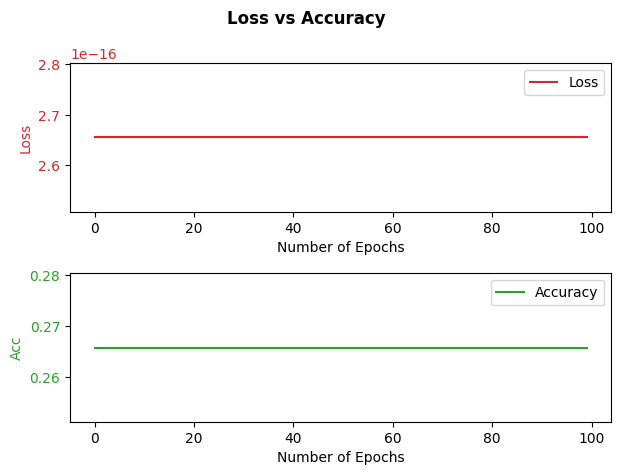

Highest Accuracy 0.2657456318569687
Accuracy:  0.26540284360189575  | Loss:  2.6519071299103283e-16
Accuracy:  0.2663507109004739  | Loss:  2.6613782268028654e-16


In [28]:
X = X_train
Y = y_train

model5 = CustomNeuralNetwork(inputLayers = [CustomLinearImplementation(30,15,act=ReLU(),drop=Dropout(0.2,inv=False),uni=1),CustomLinearImplementation(15,1,act=ReLU(),drop=Dropout(0.1,inv=False),uni=2),Softmax()],loss=CategoricalCELoss(),optimize=SGDMomentum(lr=0.1,mu=0.85))

model5.train(X,Y,epochs=100)

model5.test(X_test,y_test)
model5.test(X_val,y_val)

Epoch:  0  | Accuracy:  0.7342543681430312  | Loss:  9.178537810541759
Epoch:  1  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  2  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  3  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  4  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  5  | Accuracy:  0.7342543681430312  | Loss:  9.17854063674343
Epoch:  6  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  7  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  8  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epoch:  9  | Accuracy:  0.7342543681430312  | Loss:  9.178533614187062
Epoch:  10  | Accuracy:  0.7342543681430312  | Loss:  9.178535672166761
Epoch:  11  | Accuracy:  0.7342543681430312  | Loss:  9.178530808908405
Epoch:  12  | Accuracy:  0.7342543681430312  | Loss:  9.178530664339691
Epoch:  13  | Accuracy:  0.7342543681430312  | Loss:  9.178528956632096
Epo

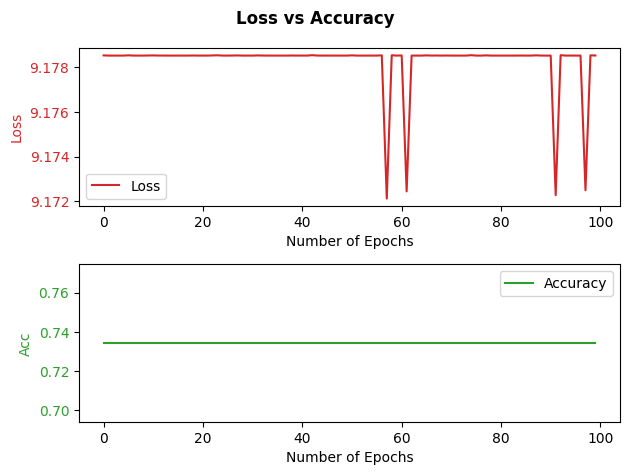

Highest Accuracy 0.7342543681430312
Accuracy:  0.7345971563981043  | Loss:  9.166689469739328
Accuracy:  0.7336492890995261  | Loss:  9.199427646416968


In [29]:
model6 = CustomNeuralNetwork(
    inputLayers=[
        CustomLinearImplementation(30,20, act=Sigmoid(), drop=Dropout(0.2,inv=False)),
        CustomLinearImplementation(20,10, act=ReLU(), drop=Dropout(0.1,inv=False)),
        CustomLinearImplementation(10,1, act=Sigmoid())
    ],
    loss=BinaryCrossEntropyLoss(),
    optimize=SGDOptimizer(lr=0.1)
)

X = X_train
Y = y_train


model6.train(X,Y,epochs=100)

model6.test(X_test,y_test)
model6.test(X_val,y_val)
